<div style="text-align: center;">

  <img src="img/LogoUesc.png" alt="UESC" style="width: 60px; display: block; margin: 0 auto 5px auto;">

  <div style="font-size: 20px;"><strong>UNIVERSIDADE ESTADUAL DE SANTA CRUZ - UESC</strong></div>
  <div style="font-size: 18px;">DEPARTAMENTO DE ENGENHARIAS E COMPUTAÇÃO - DEC</div>
  <div style="font-size: 18px;">Grupo de Pesquisas em Simulações e Controle de Processos</div>

  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

  <div style="font-size: 22px; font-weight: bold; margin-bottom: 10px;">PROGRAMAÇÃO EM PYTHON PARA AS ENGENHARIAS</div>

  <div style="font-size: 18px; margin-top: 10px;"><strong>Tema</strong>: Projeto Integrador em Engenharia Química — Da Modelagem à Simulação Computacional.</div>
  <div style="font-size: 18px;"><strong>Prof.  Dr.  E. R. Edwards</strong></div>

  <div style="font-size: 16px; margin-top: 15px;">Ilhéus - BA, Abril de 2027</div>
  
  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

</div>

**Apresentação — Um projeto completo de Engenharia Química**

Este notebook encerra a coleção **Programação em Python para as Engenharias**. O objetivo não é reunir comandos isolados, mas mostrar como o engenheiro constrói uma solução verificável: identifica um problema realista, explicita hipóteses, deduz balanços, calcula uma condição de referência, programa algoritmos, compara métodos, interpreta gráficos e avalia decisões operacionais.

**Situação-problema:** um tanque perfeitamente agitado recebe uma corrente líquida, perde calor para o ambiente e dispõe de aquecimento elétrico controlado. Desejamos prever sua temperatura, medir o processo, rejeitar perturbações e investigar o compromisso entre desempenho e consumo energético. Os dados são **hipotéticos e didáticos**. Os modelos e controladores não devem ser utilizados para comandar instalações reais nem substituir análise de riscos.

**Percurso:** fenômeno físico → hipóteses → balanços → cálculo manual → algoritmo → simulação → instrumentação → controle → otimização → comunicação técnica.

**Sumário navegável**

1. [Desafio integrador e objetivos de aprendizagem](#secao-1)
2. [Descrição física do tanque e hipóteses](#secao-2)
3. [Balanço de massa e definição do volume](#secao-3)
4. [Balanço de energia: dedução do modelo](#secao-4)
5. [Unidades, parâmetros e verificações](#secao-5)
6. [Cálculo manual do regime permanente](#secao-6)
7. [Resposta dinâmica em malha aberta](#secao-7)
8. [Método de Euler construído passo a passo](#secao-8)
9. [Comparação com solução analítica e convergência](#secao-9)
10. [Simulação com solve_ivp e validação](#secao-10)
11. [Instrumentação: transmissor e ruído](#secao-11)
12. [Tratamento de sinais e atraso de filtragem](#secao-12)
13. [Malha fechada e controlador PI](#secao-13)
14. [Saturação e anti-windup](#secao-14)
15. [Rejeição de perturbações operacionais](#secao-15)
16. [Indicadores de desempenho e energia](#secao-16)
17. [Otimização da referência de temperatura](#secao-17)
18. [Sensibilidade e incerteza paramétrica](#secao-18)
19. [Projeto final do estudante: entregáveis](#secao-19)
20. [Conclusões e percurso de aprendizagem](#secao-20)

<div id="secao-1" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">1. Desafio integrador e objetivos de aprendizagem</div>

**Problema de Engenharia.** Uma unidade precisa entregar líquido aquecido a uma temperatura próxima de uma referência, mesmo quando a alimentação muda de temperatura. A decisão operacional deve considerar a capacidade do aquecedor, a dinâmica térmica, o ruído do instrumento e o consumo de energia.

Ao final, o estudante deverá ser capaz de **deduzir e resolver** o modelo, implementar uma malha de controle, interpretar indicadores e justificar uma recomendação. A prioridade é a **interpretação física**, não a quantidade de linhas de Python.

<div id="secao-2" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">2. Descrição física do tanque e hipóteses</div>

**Sistema considerado.** Um tanque de volume constante recebe líquido a uma vazão volumétrica $F$ e temperatura $T_{in}$. A mistura é perfeita, a saída tem a temperatura interna $T$, e a potência elétrica $Q$ aquece o líquido. Há perda térmica proporcional a $T-T_a$.

**Hipóteses:** densidade $\rho$ e calor específico $c_p$ constantes; sem reação química, mudança de fase ou trabalho de eixo; vazões de entrada e saída iguais; propriedades uniformes; capacidade térmica das paredes desprezada. Essas hipóteses devem ser revistas em aplicações reais.

**Grandezas:** $V$ (m³), $F$ (m³/min), $\rho$ (kg/m³), $c_p$ (kJ/(kg·°C)), $Q$ (kJ/min), $UA$ (kJ/(min·°C)), $T$ (°C).

<div id="secao-3" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">3. Balanço de massa e definição do volume</div>

**Balanço de massa total:**

$$\frac{d(\rho V)}{dt}=\rho F_{in}-\rho F_{out}.$$

Para densidade constante e $F_{in}=F_{out}=F$:

$$\boxed{\frac{dV}{dt}=0}.$$

Portanto, o volume permanece constante. **Não** significa que o líquido esteja parado: existe renovação contínua. O tempo médio de residência hidráulica é $\tau_r=V/F$. Para $V=1{,}0$ m³ e $F=0{,}10$ m³/min, $\tau_r=10$ min.

<div id="secao-4" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">4. Balanço de energia: dedução do modelo</div>

**Balanço de energia:** acúmulo = entalpia de entrada − entalpia de saída + aquecimento − perdas. Com referência comum de entalpia e propriedades constantes:

$$\rho Vc_p\frac{dT}{dt}=\rho Fc_p(T_{in}-T)+Q-UA(T-T_a).$$

Definindo $C=\rho Vc_p$ (kJ/°C) e $H=\rho Fc_p$ (kJ/(min·°C)):

$$\boxed{\frac{dT}{dt}=\frac{H(T_{in}-T)+Q-UA(T-T_a)}{C}}.$$

**Interpretação:** a alimentação tende a aproximar $T$ de $T_{in}$; o aquecedor eleva $T$; a perda térmica tende a aproximar $T$ de $T_a$. Todas as parcelas do numerador têm unidade kJ/min.

<div id="secao-5" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">5. Unidades, parâmetros e verificações</div>

Adotaremos um conjunto de parâmetros **didáticos** e manteremos todas as unidades explícitas. Um erro frequente é misturar potência em kW com vazão de energia em kJ/min: **1 kW = 60 kJ/min**.

A função do modelo será reutilizada nas integrações numéricas, no controlador e na análise de sensibilidade. A validação de entradas usa `ValueError`; `assert` será reservado a testes de desenvolvimento.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar

PARAM = dict(V=1.0, F=0.10, rho=1000.0, cp=4.18, UA=15.0,
             Tin=25.0, Ta=25.0, Qmax=18000.0)

def propriedades(p):
    if any(p[k] <= 0 for k in ('V','F','rho','cp')) or p['UA'] < 0 or p['Qmax'] <= 0:
        raise ValueError('Parâmetros físicos fora da faixa permitida.')
    C=p['rho']*p['V']*p['cp']
    H=p['rho']*p['F']*p['cp']
    return C,H

def derivada_temperatura(T,Q,p, Tin=None):
    C,H=propriedades(p)
    Tentrada=p['Tin'] if Tin is None else Tin
    return (H*(Tentrada-T)+Q-p['UA']*(T-p['Ta']))/C

C,H=propriedades(PARAM)
print(f'Capacidade térmica: {C:.1f} kJ/°C')
print(f'Coeficiente convectivo de vazão: {H:.1f} kJ/(min·°C)')
print(f'Tempo de residência: {PARAM["V"]/PARAM["F"]:.1f} min')
print(f'Potência máxima: {PARAM["Qmax"]/60:.1f} kW')

Capacidade térmica: 4180.0 kJ/°C
Coeficiente convectivo de vazão: 418.0 kJ/(min·°C)
Tempo de residência: 10.0 min
Potência máxima: 300.0 kW


<div id="secao-6" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">6. Cálculo manual do regime permanente</div>

**Regime permanente.** No equilíbrio $dT/dt=0$, logo

$$0=H(T_{in}-T_{ss})+Q-UA(T_{ss}-T_a).$$

Isolando a temperatura:

$$\boxed{T_{ss}=\frac{HT_{in}+Q+UA T_a}{H+UA}}.$$

Para alcançar $T_{SP}=55$ °C, a potência requerida é

$$\boxed{Q_{ss}=H(T_{SP}-T_{in})+UA(T_{SP}-T_a)}.$$

**Cálculo manual:** $H=418$ kJ/(min·°C); portanto $Q_{ss}=418(55-25)+15(55-25)=12\,990$ kJ/min = **216,5 kW**. Como $Q_{max}=18\,000$ kJ/min, a referência é fisicamente atingível. Esta verificação deve preceder qualquer simulação de controle.

In [2]:
Tsp=55.0
Qss=H*(Tsp-PARAM['Tin'])+PARAM['UA']*(Tsp-PARAM['Ta'])
Tss=(H*PARAM['Tin']+Qss+PARAM['UA']*PARAM['Ta'])/(H+PARAM['UA'])
print(f'Q necessário = {Qss:,.1f} kJ/min = {Qss/60:.1f} kW')
print(f'Temperatura estacionária = {Tss:.2f} °C')
print('Referência alcançável?',Qss<=PARAM['Qmax'])
assert np.isclose(Tss,Tsp)

Q necessário = 12,990.0 kJ/min = 216.5 kW
Temperatura estacionária = 55.00 °C
Referência alcançável? True


<div id="secao-7" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">7. Resposta dinâmica em malha aberta</div>

**Dinâmica em malha aberta.** Para potência e alimentação constantes, o balanço tem a forma

$$\frac{dT}{dt}=\frac{T_{ss}-T}{\tau},\qquad \tau=\frac{C}{H+UA}.$$

A solução analítica é

$$\boxed{T(t)=T_{ss}+(T_0-T_{ss})e^{-t/\tau}}.$$

Com $C=4180$ kJ/°C e $H+UA=433$ kJ/(min·°C), $\tau\approx9{,}65$ min. Após uma constante de tempo, o tanque percorre cerca de 63,2% da diferença entre a condição inicial e o equilíbrio. Essa constante de tempo não é necessariamente igual ao tempo de residência $V/F$ porque há perdas térmicas.

Constante de tempo: 9.654 min
T(tau): 43.964 °C


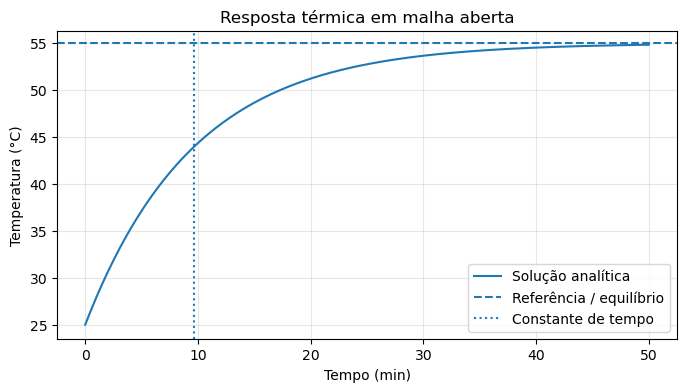

In [3]:
tau=C/(H+PARAM['UA'])
t=np.linspace(0,50,501)
T0=25.0
T_analitica=Tss+(T0-Tss)*np.exp(-t/tau)
print(f'Constante de tempo: {tau:.3f} min')
print(f'T(tau): {Tss+(T0-Tss)*np.exp(-1):.3f} °C')
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(t,T_analitica,label='Solução analítica')
ax.axhline(Tsp,ls='--',label='Referência / equilíbrio')
ax.axvline(tau,ls=':',label='Constante de tempo')
ax.set(xlabel='Tempo (min)',ylabel='Temperatura (°C)',title='Resposta térmica em malha aberta')
ax.grid(alpha=.3);ax.legend();plt.show()

<div id="secao-8" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">8. Método de Euler construído passo a passo</div>

**Algoritmo de Euler explícito.** Em vez de começar por uma biblioteca, discretizamos o balanço:

$$T_{k+1}=T_k+\Delta t\,\frac{H(T_{in}-T_k)+Q-UA(T_k-T_a)}{C}.$$

**Primeiro passo manual:** com $T_0=25$ °C, $Q=12\,990$ kJ/min e $\Delta t=1$ min, os termos de alimentação e perda são inicialmente nulos. Logo $T_1=25+12990/4180\approx28{,}108$ °C. O cálculo manual é um teste de consistência para o algoritmo.

In [4]:
def euler_tanque(T0,Q,tf,dt,p):
    if dt<=0 or tf<=0 or not np.isclose(tf/dt,round(tf/dt)):
        raise ValueError('Use tempos positivos e tf múltiplo de dt.')
    n=int(round(tf/dt))
    tt=np.arange(n+1)*dt
    TT=np.empty(n+1);TT[0]=T0
    for k in range(n):
        TT[k+1]=TT[k]+dt*derivada_temperatura(TT[k],Q,p)
    return tt,TT

t_euler,T_euler=euler_tanque(25,Qss,50,1,PARAM)
primeiro_manual=25+Qss/C
print(f'Primeiro passo manual: {primeiro_manual:.6f} °C')
print(f'Primeiro passo Euler:  {T_euler[1]:.6f} °C')
assert np.isclose(primeiro_manual,T_euler[1])

Primeiro passo manual: 28.107656 °C
Primeiro passo Euler:  28.107656 °C


<div id="secao-9" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">9. Comparação com solução analítica e convergência</div>

**Verificação de convergência.** A solução analítica permite avaliar o erro do método de Euler sem confundir erro de discretização com fenômeno físico. Reduziremos $\Delta t$ e compararemos as temperaturas no mesmo instante.

A condição de estabilidade de Euler para esta equação linear é $0<\Delta t<2\tau$; contudo, **estabilidade não garante precisão**. A comparação deve demonstrar a diminuição do erro quando o passo é refinado.

dt=2.00 min | erro máximo=1.2501 °C
dt=1.00 min | erro máximo=0.5973 °C
dt=0.25 min | erro máximo=0.1445 °C


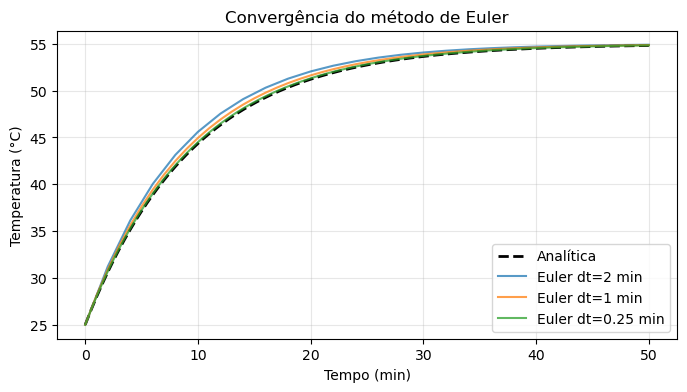

In [5]:
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(t,T_analitica,'k--',lw=2,label='Analítica')
for passo in [2.0,1.0,0.25]:
    tt,TT=euler_tanque(25,Qss,50,passo,PARAM)
    ex=Tss+(25-Tss)*np.exp(-tt/tau)
    erro_max=np.max(np.abs(TT-ex))
    print(f'dt={passo:4.2f} min | erro máximo={erro_max:.4f} °C')
    ax.plot(tt,TT,label=f'Euler dt={passo:g} min',alpha=.75)
ax.set(xlabel='Tempo (min)',ylabel='Temperatura (°C)',title='Convergência do método de Euler')
ax.grid(alpha=.3);ax.legend();plt.show()

<div id="secao-10" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">10. Simulação com solve_ivp e validação</div>

**Comparação com um integrador pronto.** Após compreender o algoritmo de Euler, utilizaremos `solve_ivp` do SciPy, que disponibiliza integradores adaptativos. A comparação não prova que qualquer integrador seja infalível; ela verifica se **duas implementações independentes** concordam com a solução conhecida dentro de uma tolerância definida.

In [6]:
sol=solve_ivp(lambda tt,y:[derivada_temperatura(y[0],Qss,PARAM)],
              (0,50),[25.0],t_eval=t,rtol=1e-9,atol=1e-10)
if not sol.success: raise RuntimeError(sol.message)
T_ivp=sol.y[0]
maior_erro=np.max(np.abs(T_ivp-T_analitica))
print(f'Diferença máxima solve_ivp × solução analítica: {maior_erro:.3e} °C')
assert maior_erro<1e-5

Diferença máxima solve_ivp × solução analítica: 1.057e-08 °C


<div id="secao-11" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">11. Instrumentação: transmissor e ruído</div>

**Instrumentação.** O controlador não recebe diretamente a temperatura verdadeira. Consideremos um transmissor ideal de **4 a 20 mA** calibrado para **0 a 100 °C**:

$$I=4+16\frac{T}{100}\quad\mathrm{(mA)},\qquad T=100\frac{I-4}{16}\quad\mathrm{(^\circ C)}.$$

Para $T=55$ °C, o cálculo manual resulta em $I=4+16(55/100)=12{,}8$ mA. Acrescentaremos ruído sintético à corrente e reconstruiremos a temperatura. A conversão não corrige desvios de calibração, falhas ou atrasos físicos.

Corrente ideal a 55 °C: 12.8 mA
Desvio-padrão do ruído em °C (amostra): 0.26268671436408897


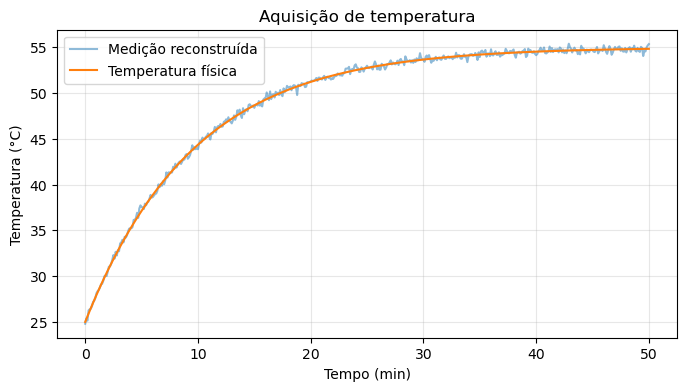

In [7]:
def temp_para_corrente(T): return 4+16*np.asarray(T)/100
def corrente_para_temp(I): return 100*(np.asarray(I)-4)/16
rng=np.random.default_rng(2026)
I_limpo=temp_para_corrente(T_analitica)
I_ruidoso=I_limpo+rng.normal(0,0.04,size=t.size)
T_medida=corrente_para_temp(I_ruidoso)
print('Corrente ideal a 55 °C:',temp_para_corrente(55),'mA')
print('Desvio-padrão do ruído em °C (amostra):',np.std(T_medida-T_analitica,ddof=1))
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(t,T_medida,alpha=.5,label='Medição reconstruída')
ax.plot(t,T_analitica,label='Temperatura física')
ax.set(xlabel='Tempo (min)',ylabel='Temperatura (°C)',title='Aquisição de temperatura')
ax.grid(alpha=.3);ax.legend();plt.show()

<div id="secao-12" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">12. Tratamento de sinais e atraso de filtragem</div>

**Filtragem e compromisso dinâmico.** Um filtro exponencial causal é descrito por

$$y_k=\alpha x_k+(1-\alpha)y_{k-1},\qquad 0<\alpha\leq1.$$

O filtro reduz flutuações de alta frequência, mas introduz atraso. Em uma malha de controle, isso pode prejudicar a resposta às perturbações. O estudante deve comparar a suavização visual com o erro efetivo em relação à temperatura física.

RMSE da medição: 0.263 °C
RMSE filtrado:   0.379 °C


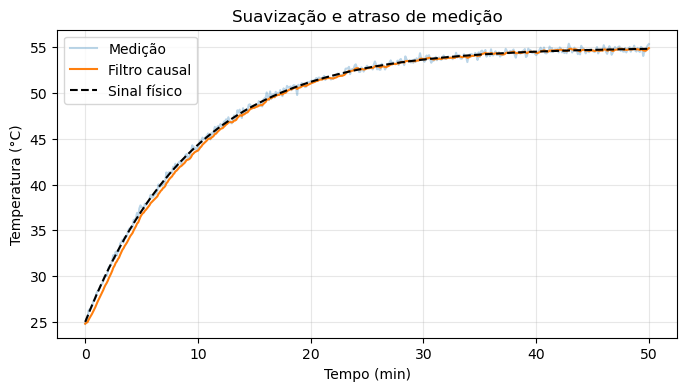

In [8]:
def filtro_exponencial(x,alpha):
    if not 0<alpha<=1: raise ValueError('alpha deve estar em (0,1].')
    x=np.asarray(x,dtype=float);y=np.empty_like(x);y[0]=x[0]
    for k in range(1,len(x)): y[k]=alpha*x[k]+(1-alpha)*y[k-1]
    return y

T_filtrada=filtro_exponencial(T_medida,0.2)
rmse_medida=np.sqrt(np.mean((T_medida-T_analitica)**2))
rmse_filtrada=np.sqrt(np.mean((T_filtrada-T_analitica)**2))
print(f'RMSE da medição: {rmse_medida:.3f} °C')
print(f'RMSE filtrado:   {rmse_filtrada:.3f} °C')
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(t,T_medida,alpha=.3,label='Medição')
ax.plot(t,T_filtrada,label='Filtro causal')
ax.plot(t,T_analitica,'k--',label='Sinal físico')
ax.set(xlabel='Tempo (min)',ylabel='Temperatura (°C)',title='Suavização e atraso de medição')
ax.grid(alpha=.3);ax.legend();plt.show()

<div id="secao-13" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">13. Malha fechada e controlador PI</div>

**Controle de temperatura.** Utilizaremos uma forma **PI com polarização** na potência estacionária $Q_b$:

$$e_k=T_{SP}-T_{m,k},\qquad Q_k^*=Q_b+K_p e_k+K_i\int e\,dt.$$

Os ganhos $K_p$ (kJ/(min·°C)) e $K_i$ (kJ/(min²·°C)) são escolhidos **apenas para simulação**. A potência física é limitada a $0\leq Q\leq Q_{max}$.

Para separar a resposta ao controlador da resposta de partida, iniciaremos o tanque a **45 °C**, com referência de **55 °C**. A implementação seguinte atualiza a medição, o controlador e o balanço de energia em cada passo, sem usar informações futuras.

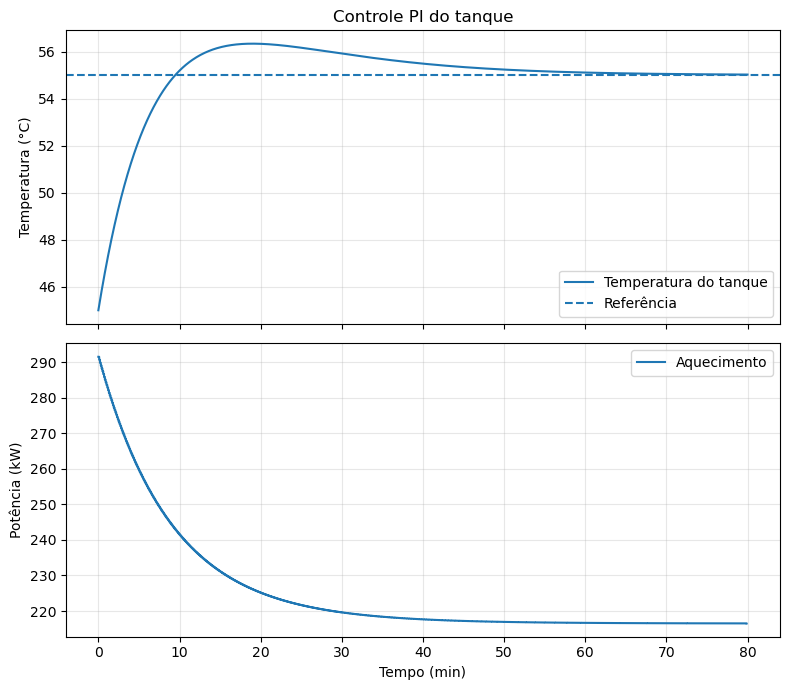

Temperatura final: 55.021 °C


In [9]:
def simular_pi(p, T0=45.0, sp=55.0, tf=80.0, dt=0.1,
               kp=450.0,ki=45.0, t_pert=None, Tin_apos=None,
               antiwindup=True, ruido_mA=0.0, semente=10):
    if dt<=0 or tf<=0 or not np.isclose(tf/dt,round(tf/dt)):
        raise ValueError('Passo temporal inválido.')
    C,H=propriedades(p)
    n=int(round(tf/dt));tt=np.arange(n+1)*dt
    T=np.empty(n+1);T[0]=T0
    Q=np.empty(n);E=np.empty(n);Tin_hist=np.empty(n)
    I=np.empty(n);med=np.empty(n)
    integ=0.0;ger=np.random.default_rng(semente)
    Qb=H*(sp-p['Tin'])+p['UA']*(sp-p['Ta'])
    for k in range(n):
        Tin=p['Tin'] if t_pert is None or tt[k]<t_pert else Tin_apos
        Tin_hist[k]=Tin
        I[k]=float(temp_para_corrente(T[k]))+ger.normal(0,ruido_mA)
        med[k]=float(corrente_para_temp(I[k]))
        E[k]=sp-med[k]
        livre=Qb+kp*E[k]+ki*integ
        Q[k]=np.clip(livre,0,p['Qmax'])
        if (not antiwindup or
            ((livre<p['Qmax'] or E[k]<0) and (livre>0 or E[k]>0))):
            integ+=E[k]*dt
        T[k+1]=T[k]+dt*derivada_temperatura(T[k],Q[k],p,Tin=Tin)
    return dict(t=tt,T=T,Q=Q,e=E,Tin=Tin_hist,I=I,med=med)

controle=simular_pi(PARAM)
fig,axs=plt.subplots(2,1,figsize=(8,7),sharex=True)
axs[0].plot(controle['t'],controle['T'],label='Temperatura do tanque')
axs[0].axhline(55,ls='--',label='Referência')
axs[0].set(ylabel='Temperatura (°C)',title='Controle PI do tanque')
axs[0].grid(alpha=.3);axs[0].legend()
axs[1].step(controle['t'][:-1],controle['Q']/60,where='post',label='Aquecimento')
axs[1].set(xlabel='Tempo (min)',ylabel='Potência (kW)')
axs[1].grid(alpha=.3);axs[1].legend()
plt.tight_layout();plt.show()
print(f'Temperatura final: {controle["T"][-1]:.3f} °C')

<div id="secao-14" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">14. Saturação e anti-windup</div>

**Saturação e anti-windup.** Quando a potência requerida excede $Q_{max}$, o aquecedor satura. Se a integral continuar acumulando erro, o controlador pode demorar a recuperar a operação normal. A integração condicional suspende o acúmulo quando o erro reforça a saturação.

Para tornar o efeito observável, usaremos uma referência **temporariamente inalcançável de 75 °C** com o mesmo aquecedor. Nesse caso, o equilíbrio máximo é $T_{max}=(HT_{in}+Q_{max}+UA T_a)/(H+UA)$. Se $T_{SP}>T_{max}$, nenhuma sintonia de PI pode eliminar o erro de regime permanente.

Temperatura máxima estacionária possível: 66.57 °C
Referência de 75 °C alcançável? False


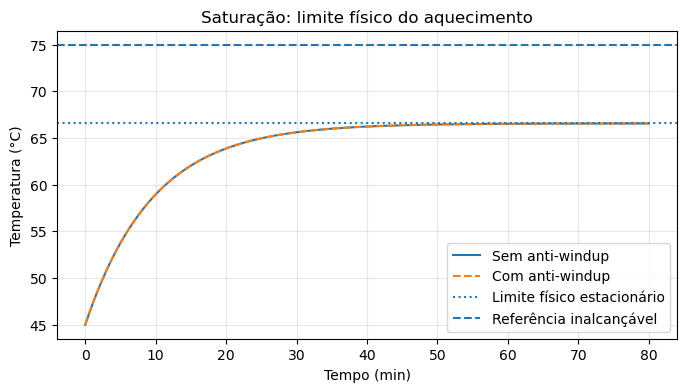

Observação: com referência fixa inalcançável, ambas as temperaturas podem coincidir;
a vantagem do anti-windup aparece sobretudo após o retorno a uma condição alcançável.


In [10]:
Tmax=(H*PARAM['Tin']+PARAM['Qmax']+PARAM['UA']*PARAM['Ta'])/(H+PARAM['UA'])
sem_aw=simular_pi(PARAM,sp=75,tf=80,ki=120,antiwindup=False)
com_aw=simular_pi(PARAM,sp=75,tf=80,ki=120,antiwindup=True)
print(f'Temperatura máxima estacionária possível: {Tmax:.2f} °C')
print(f'Referência de 75 °C alcançável? {75<=Tmax}')
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(sem_aw['t'],sem_aw['T'],label='Sem anti-windup')
ax.plot(com_aw['t'],com_aw['T'],'--',label='Com anti-windup')
ax.axhline(Tmax,ls=':',label='Limite físico estacionário')
ax.axhline(75,ls='--',label='Referência inalcançável')
ax.set(xlabel='Tempo (min)',ylabel='Temperatura (°C)',title='Saturação: limite físico do aquecimento')
ax.grid(alpha=.3);ax.legend();plt.show()
print('Observação: com referência fixa inalcançável, ambas as temperaturas podem coincidir;')
print('a vantagem do anti-windup aparece sobretudo após o retorno a uma condição alcançável.')

<div id="secao-15" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">15. Rejeição de perturbações operacionais</div>

**Perturbação de alimentação.** Aos 30 min, a temperatura da alimentação cairá de 25 para 20 °C. Isso reduz a energia que entra no tanque. A malha PI deverá aumentar a potência para recuperar a referência, desde que haja margem no atuador.

No novo regime, a potência necessária é $Q_{ss,novo}=H(55-20)+UA(55-25)=15\,080$ kJ/min, ainda inferior a $Q_{max}=18\,000$ kJ/min. O cálculo manual permite antecipar o comportamento esperado.

Potência estacionária após perturbação: 15080.0 kJ/min = 251.3 kW


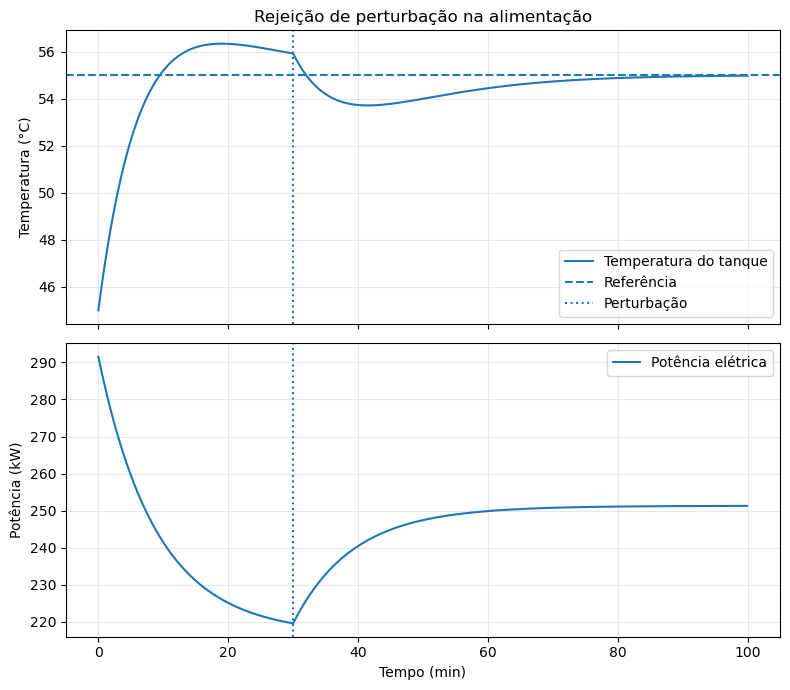

In [11]:
pert=simular_pi(PARAM,tf=100,t_pert=30,Tin_apos=20)
Q_novo=H*(55-20)+PARAM['UA']*(55-PARAM['Ta'])
print(f'Potência estacionária após perturbação: {Q_novo:.1f} kJ/min = {Q_novo/60:.1f} kW')
fig,axs=plt.subplots(2,1,figsize=(8,7),sharex=True)
axs[0].plot(pert['t'],pert['T'],label='Temperatura do tanque')
axs[0].axhline(55,ls='--',label='Referência')
axs[0].axvline(30,ls=':',label='Perturbação')
axs[0].set(ylabel='Temperatura (°C)',title='Rejeição de perturbação na alimentação')
axs[0].grid(alpha=.3);axs[0].legend()
axs[1].plot(pert['t'][:-1],pert['Q']/60,label='Potência elétrica')
axs[1].axvline(30,ls=':')
axs[1].set(xlabel='Tempo (min)',ylabel='Potência (kW)')
axs[1].grid(alpha=.3);axs[1].legend()
plt.tight_layout();plt.show()

<div id="secao-16" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">16. Indicadores de desempenho e energia</div>

**Indicadores de desempenho.** A integral do erro absoluto (IAE) quantifica a magnitude acumulada do desvio:

$$IAE\approx\sum_{k=0}^{N-1}|e_k|\Delta t.$$

Para medir consumo, calculamos a energia elétrica fornecida: $E_Q=\sum Q_k\Delta t$ (kJ). Convertendo, $1\,\mathrm{kWh}=3600\,\mathrm{kJ}$. O consumo de uma partida depende da condição inicial e do horizonte de simulação: **não se deve comparar cenários com horizontes diferentes sem contextualização**.

Também verificaremos a conservação de energia no modelo discretizado. Para Euler, a variação de energia armazenada deve coincidir, até erro de arredondamento, com a soma dos fluxos energéticos utilizados em cada passo.

In [12]:
dt=0.1
iae=np.sum(np.abs(pert['e']))*dt
energia_kJ=np.sum(pert['Q'])*dt
fluxo=H*(pert['Tin']-pert['T'][:-1])+pert['Q']-PARAM['UA']*(pert['T'][:-1]-PARAM['Ta'])
residuo=C*(pert['T'][-1]-pert['T'][0])-np.sum(fluxo)*dt
print(f'IAE (com erro de medição ideal): {iae:.2f} °C·min')
print(f'Energia fornecida: {energia_kJ/3600:.2f} kWh')
print(f'Resíduo do balanço energético discreto: {residuo:.3e} kJ')
assert abs(residuo)<1e-6

IAE (com erro de medição ideal): 91.79 °C·min
Energia fornecida: 407.50 kWh
Resíduo do balanço energético discreto: -1.019e-10 kJ


<div id="secao-17" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">17. Otimização da referência de temperatura</div>

**Otimização e tomada de decisão.** Uma temperatura de operação mais elevada aumenta a energia requerida; uma temperatura mais baixa pode prejudicar a qualidade do produto. Para ilustrar o compromisso, adotaremos uma **penalidade didática de qualidade** mínima em 55 °C:

$$J(T_{SP})=\left(\frac{Q_{ss}(T_{SP})}{1000}\right)^2+\lambda(T_{SP}-55)^2.$$

O primeiro termo penaliza potência de aquecimento, o segundo penaliza afastamento da temperatura-alvo. **Não se trata de um modelo econômico validado**: a ponderação $\lambda$ foi escolhida para fins de aprendizagem. Restringiremos $T_{SP}$ ao intervalo de 45 a 60 °C e exigiremos $Q_{ss}\le Q_{max}$. Antes do SciPy, discutiremos que reduzir $T_{SP}$ diminui a energia, mas aumenta a penalidade de qualidade.

Busca em malha: 54.550 °C
SciPy: 54.538 °C
Potência correspondente: 213.17 kW


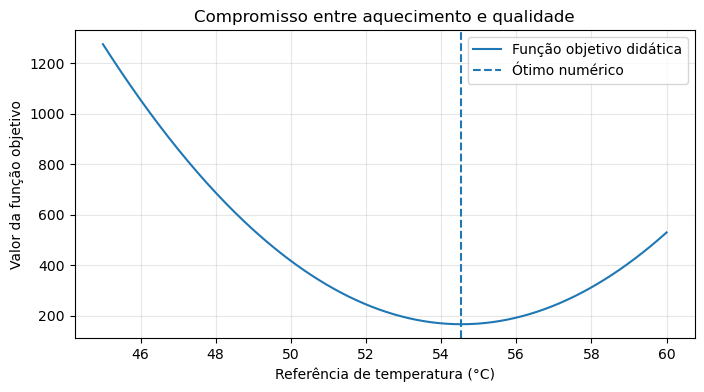

In [13]:
peso_qualidade=12.0
def potencia_estacionaria(sp,p=PARAM):
    C_,H_=propriedades(p)
    return H_*(sp-p['Tin'])+p['UA']*(sp-p['Ta'])
def objetivo(sp):
    q=potencia_estacionaria(sp)
    return (q/1000)**2+peso_qualidade*(sp-55)**2

sp_grid=np.linspace(45,60,301)
valores=np.array([objetivo(sp) for sp in sp_grid])
sp_malha=sp_grid[np.argmin(valores)]
limite_sp=min(60,(H*PARAM['Tin']+PARAM['Qmax']+PARAM['UA']*PARAM['Ta'])/(H+PARAM['UA']))
resultado=minimize_scalar(objetivo,bounds=(45,limite_sp),method='bounded')
if not resultado.success: raise RuntimeError('Falha na otimização')
print(f'Busca em malha: {sp_malha:.3f} °C')
print(f'SciPy: {resultado.x:.3f} °C')
print(f'Potência correspondente: {potencia_estacionaria(resultado.x)/60:.2f} kW')
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(sp_grid,valores,label='Função objetivo didática')
ax.axvline(resultado.x,ls='--',label='Ótimo numérico')
ax.set(xlabel='Referência de temperatura (°C)',ylabel='Valor da função objetivo',title='Compromisso entre aquecimento e qualidade')
ax.grid(alpha=.3);ax.legend();plt.show()

<div id="secao-18" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">18. Sensibilidade e incerteza paramétrica</div>

**Sensibilidade paramétrica.** Os parâmetros $F$ e $UA$ raramente são conhecidos sem incerteza. Um modelo útil deve indicar como a previsão muda quando esses parâmetros variam.

Aqui, manteremos a potência calculada para 55 °C no caso nominal e avaliaremos o equilíbrio para vazões entre 0,08 e 0,12 m³/min e $UA$ entre 10 e 20 kJ/(min·°C). Não atribuiremos probabilidades a esses cenários; trata-se de uma **análise determinística de sensibilidade**, não de uma estimativa estatística de incerteza.

In [14]:
cenarios=[]
for F_teste in [0.08,0.10,0.12]:
    for UA_teste in [10.0,15.0,20.0]:
        p=dict(PARAM,F=F_teste,UA=UA_teste)
        _,h=propriedades(p)
        equilibrio=(h*p['Tin']+Qss+UA_teste*p['Ta'])/(h+UA_teste)
        cenarios.append(dict(F_m3_min=F_teste,UA_kJ_min_C=UA_teste,Tss_C=equilibrio))
tabela=pd.DataFrame(cenarios)
print(tabela.round(3).to_string(index=False))
print(f'Faixa de temperaturas previstas: {tabela.Tss_C.min():.2f} a {tabela.Tss_C.max():.2f} °C')

 F_m3_min  UA_kJ_min_C  Tss_C
     0.08         10.0 62.718
     0.08         15.0 62.178
     0.08         20.0 61.653
     0.10         10.0 55.350
     0.10         15.0 55.000
     0.10         20.0 54.658
     0.12         10.0 50.391
     0.12         15.0 50.145
     0.12         20.0 49.904
Faixa de temperaturas previstas: 49.90 a 62.72 °C


<div id="secao-19" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">19. Projeto final do estudante: entregáveis</div>

**Desafio final — sua versão do projeto.** Agora o estudante deve atuar como engenheiro: propor uma mudança de processo, justificá-la fisicamente, deduzir as equações alteradas, testar o algoritmo e defender a decisão. Sugestões: modificar a vazão de alimentação, considerar variação da temperatura ambiente, introduzir um limite de potência mais rigoroso ou comparar dois conjuntos de ganhos PI.

**Entregáveis sugeridos:** (1) enunciado e diagrama esquemático do processo; (2) hipóteses, grandezas e unidades; (3) balanços deduzidos; (4) um cálculo manual verificável; (5) código comentado e executável; (6) pelo menos dois gráficos com eixos e unidades; (7) comparação de cenários com indicadores; (8) discussão das limitações físicas, numéricas e de instrumentação; (9) conclusão com recomendação fundamentada.

**Critérios de avaliação (100 pontos):** fundamentação física e hipóteses (20), dedução e cálculo manual (20), algoritmo e validação (20), interpretação dos resultados (20), qualidade da comunicação técnica e reprodutibilidade (20).

**Perguntas para reflexão:** O modelo respeita as leis de conservação? O atuador consegue alcançar a referência? Um gráfico suave significa medição correta? Uma solução numérica ótima é automaticamente uma boa decisão de Engenharia?

<div id="secao-20" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">20. Conclusões e percurso de aprendizagem</div>

O projeto integrou programação básica, funções confiáveis, estruturas de dados, NumPy, visualização, métodos numéricos, equações diferenciais, balanços de massa e energia, transferência de calor, instrumentação, controle e otimização. A contribuição central da computação científica não é esconder os fenômenos em bibliotecas, mas **tornar os modelos testáveis e as decisões justificáveis**.

Ao concluir esta coleção, o estudante deve ser capaz de formular perguntas de Engenharia, construir modelos proporcionais ao problema, verificar resultados com diferentes métodos e comunicar com clareza o que a simulação demonstra — e, igualmente importante, **o que ela não demonstra**.

**Mensagem final:** a ferramenta computacional amplia a capacidade de análise do engenheiro; a responsabilidade pela formulação, interpretação e decisão permanece humana.

<div style="text-align: center; font-size: 12px; color: gray; margin-top: 40px; padding-top: 15px; border-top: 1px solid #dddddd;">
Material desenvolvido pelo Grupo de Pesquisas em Modelagem Computacional da UESC.<br>
© 2026 — Todos os direitos reservados. Uso comercial somente mediante autorização.
</div>